## 1. Imports, đường dẫn và cấu hình

Giữ cách làm sạch, split và kích thước vocabulary gần với LAB 05 để kết quả có thể so sánh. Mô hình sử dụng toàn bộ dữ liệu sau khi bỏ review trùng.

In [1]:
from pathlib import Path
from collections import Counter
import copy
import html
import re
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

try:
    import torch
    from torch import nn
    from torch.nn.utils.rnn import pack_padded_sequence
    from torch.utils.data import DataLoader, Dataset
except ImportError as error:
    raise ImportError(
        "Chưa có PyTorch. Cài bằng: python -m pip install torch"
    ) from error

CURRENT_DIR = Path.cwd().resolve()
lab_candidates = [CURRENT_DIR, CURRENT_DIR / "lab06", CURRENT_DIR.parent / "lab06"]
for parent in CURRENT_DIR.parents:
    lab_candidates.append(parent / "lab06")
LAB_DIR = next(
    (candidate for candidate in lab_candidates
     if (candidate / "W6.pdf").exists()),
    None,
)
if LAB_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục lab06 chứa W6.pdf.")

PROJECT_DIR = LAB_DIR.parent
DATA_PATH = PROJECT_DIR / "data" / "IMDB Dataset.csv"
RESULTS_PATH = LAB_DIR / "results.csv"
ATTENTION_HEATMAP_PATH = LAB_DIR / "attention_heatmap.png"
CONFUSION_MATRIX_PATH = LAB_DIR / "confusion_matrix.png"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy IMDb: {DATA_PATH}")

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20
MAX_VOCAB_SIZE = 30_000
MIN_WORD_FREQUENCY = 2
BASE_MAX_LENGTH = 100
EMBEDDING_DIM = 64
HIDDEN_SIZE = 64
BATCH_SIZE = 128
MAX_EPOCHS = 5
LEARNING_RATE = 1e-3
EARLY_STOPPING_PATIENCE = 2
GRADIENT_CLIP_NORM = 1.0
PAD_ID = 0
UNK_ID = 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
results_rows = []

RESULT_COLUMNS = [
    "experiment", "model", "representation", "split",
    "accuracy", "precision_positive", "recall_positive",
    "f1_positive", "f1_macro", "validation_loss", "test_loss",
    "training_time_seconds", "epochs_trained", "parameters",
    "sequence_length", "vocabulary_size", "temperature",
    "max_attention_weight", "attention_entropy",
    "attention_matrix_elements", "query", "token", "score",
    "attention_weight", "notes",
]

def add_result_row(experiment, **values):
    row = {column: np.nan for column in RESULT_COLUMNS}
    row["experiment"] = experiment
    row.update(values)
    results_rows.append(row)

print(f"Thiết bị: {DEVICE}")
print(f"Dataset: {DATA_PATH}")
print(f"PyTorch: {torch.__version__}")


Thiết bị: cpu
Dataset: C:\Users\KIEN\OneDrive\Máy tính\NLP\data\IMDB Dataset.csv
PyTorch: 2.14.1+cpu


## 2. Đọc IMDb và làm sạch dữ liệu

Giữ từ phủ định như not. Loại review thiếu/rỗng, duplicate có nhãn mâu thuẫn và duplicate cùng nhãn trước khi chia dữ liệu.

In [2]:
TEXT_COLUMN = "review"
LABEL_COLUMN = "sentiment"
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?", flags=re.IGNORECASE)

def normalize_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text.lower()).strip()

def tokenize(text):
    return TOKEN_PATTERN.findall(text)

raw_df = pd.read_csv(DATA_PATH, encoding="utf-8")
missing_columns = {TEXT_COLUMN, LABEL_COLUMN} - set(raw_df.columns)
if missing_columns:
    raise KeyError(f"Thiếu cột: {sorted(missing_columns)}")

missing_review_count = int(raw_df[TEXT_COLUMN].isna().sum())
missing_label_count = int(raw_df[LABEL_COLUMN].isna().sum())
data = raw_df[[TEXT_COLUMN, LABEL_COLUMN]].dropna().copy()
data[TEXT_COLUMN] = data[TEXT_COLUMN].map(normalize_review)
data[LABEL_COLUMN] = data[LABEL_COLUMN].astype(str).str.strip().str.lower()
data = data[data[TEXT_COLUMN].map(lambda text: len(tokenize(text)) > 0)].copy()

unexpected_labels = set(data[LABEL_COLUMN].unique()) - {"positive", "negative"}
if unexpected_labels:
    raise ValueError(f"Nhãn ngoài dự kiến: {unexpected_labels}")

label_counts_per_review = data.groupby(TEXT_COLUMN)[LABEL_COLUMN].nunique()
conflicting_reviews = set(label_counts_per_review[label_counts_per_review > 1].index)
conflicting_rows_removed = int(data[TEXT_COLUMN].isin(conflicting_reviews).sum())
data = data[~data[TEXT_COLUMN].isin(conflicting_reviews)].copy()

duplicate_rows_removed = int(data[TEXT_COLUMN].duplicated().sum())
data = data.drop_duplicates(subset=[TEXT_COLUMN], keep="first").reset_index(drop=True)
data["label_id"] = data[LABEL_COLUMN].map({"negative": 0, "positive": 1}).astype(int)
data["token_length"] = data[TEXT_COLUMN].map(lambda text: len(tokenize(text)))

display(pd.DataFrame([{
    "Số dòng ban đầu": len(raw_df),
    "Review thiếu": missing_review_count,
    "Nhãn thiếu": missing_label_count,
    "Dòng xung đột nhãn đã bỏ": conflicting_rows_removed,
    "Review trùng đã bỏ": duplicate_rows_removed,
    "Số review sau làm sạch": len(data),
}]))
display(data[[TEXT_COLUMN, LABEL_COLUMN]].head(3))


,Số dòng ban đầu,Review thiếu,Nhãn thiếu,Dòng xung đột nhãn đã bỏ,Review trùng đã bỏ,Số review sau làm sạch
0,50000,0,0,0,422,49578


,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive


## 3. Experiment 1 — Phân phối độ dài sequence

Đếm token bằng cùng một tokenizer cho tất cả review. Dựa vào trung vị/phân vị và histogram khi chọn BASE_MAX_LENGTH.

,Nhãn,Số review,Tỷ lệ (%)
0,positive,24882,50.187583
1,negative,24696,49.812417


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Số token,49578.0,231.205958,171.090937,6.0,127.0,173.0,280.0,451.3,589.0,903.0,2473.0


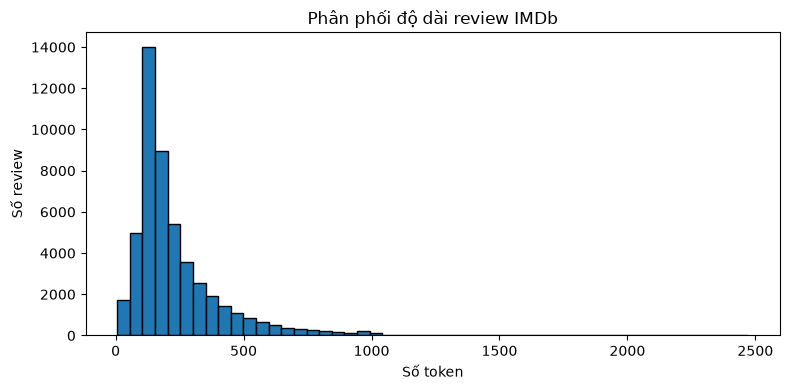

In [3]:
class_distribution = (
    data[LABEL_COLUMN]
    .value_counts()
    .rename_axis("Nhãn")
    .reset_index(name="Số review")
)
class_distribution["Tỷ lệ (%)"] = (
    class_distribution["Số review"] / class_distribution["Số review"].sum() * 100
)
display(class_distribution)

length_summary = data["token_length"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("Số token").T
display(length_summary)

plt.figure(figsize=(8, 4))
plt.hist(data["token_length"], bins=50, edgecolor="black")
plt.xlabel("Số token")
plt.ylabel("Số review")
plt.title("Phân phối độ dài review IMDb")
plt.tight_layout()
plt.show()


**Nhận xét — Experiment 1**

Dựa trên phân phối độ dài, BASE_MAX_LENGTH có giữ được phần lớn review không? Dữ liệu nào trong bảng/histogram hỗ trợ lựa chọn?

Nhận xét: BASE_MAX_LENGTH=100 thấp hơn trung vị 173 token, nên hơn một nửa review dài hơn ngưỡng này; phân vị 90% là 451 và độ dài lớn nhất 2.473 token. Độ dài 100 thuận tiện để so sánh với LAB 05, nhưng sẽ cắt nhiều review dài.

## 4. Train / validation / test split

Dùng stratified 60/20/20 và seed cố định. Vocabulary chỉ được học từ train để tránh leakage.

In [4]:
texts = data[TEXT_COLUMN].tolist()
labels = data["label_id"].to_numpy(dtype=np.int64)

x_train_val, x_test, y_train_val, y_test = train_test_split(
    texts,
    labels,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=labels,
)
relative_validation_size = VALIDATION_SIZE / (1 - TEST_SIZE)
x_train, x_validation, y_train, y_validation = train_test_split(
    x_train_val,
    y_train_val,
    test_size=relative_validation_size,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

split_table = pd.DataFrame([
    {"Tập": "Train", "Số review": len(x_train)},
    {"Tập": "Validation", "Số review": len(x_validation)},
    {"Tập": "Test", "Số review": len(x_test)},
])
display(split_table)


,Tập,Số review
0,Train,29746
1,Validation,9916
2,Test,9916


## 5. Token IDs và vocabulary

Dùng vocabulary word-level giới hạn ở 30.000 token; ID 0 là PAD, ID 1 là UNK. Tất cả classifier dùng chung encoded data.

In [5]:
word_counts = Counter()
for review in x_train:
    word_counts.update(tokenize(review))

vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
for word, count in word_counts.most_common():
    if count < MIN_WORD_FREQUENCY or len(vocab) >= MAX_VOCAB_SIZE:
        break
    vocab[word] = len(vocab)

id_to_word = {index: word for word, index in vocab.items()}
VOCAB_SIZE = len(vocab)

def encode_reviews(review_list, vocabulary, max_length):
    encoded = np.zeros((len(review_list), max_length), dtype=np.int32)
    lengths = np.zeros(len(review_list), dtype=np.int32)
    token_lists = []

    for row_index, review in enumerate(review_list):
        tokens = tokenize(review)[:max_length]
        token_lists.append(tokens)
        token_ids = [vocabulary.get(token, UNK_ID) for token in tokens]
        lengths[row_index] = len(token_ids)
        if token_ids:
            encoded[row_index, :len(token_ids)] = token_ids

    return encoded, lengths, token_lists

x_train_ids, train_lengths, train_tokens = encode_reviews(
    x_train, vocab, BASE_MAX_LENGTH
)
x_validation_ids, validation_lengths, validation_tokens = encode_reviews(
    x_validation, vocab, BASE_MAX_LENGTH
)
x_test_ids, test_lengths, test_tokens = encode_reviews(
    x_test, vocab, BASE_MAX_LENGTH
)

print(f"Vocabulary gồm PAD/UNK: {VOCAB_SIZE:,}")
print("Train IDs:", x_train_ids.shape)
print("Validation IDs:", x_validation_ids.shape)
print("Test IDs:", x_test_ids.shape)
display(pd.DataFrame({
    "Token mẫu": train_tokens[0][:15],
    "Token ID": [vocab.get(token, UNK_ID) for token in train_tokens[0][:15]],
}))


Vocabulary gồm PAD/UNK: 30,000
Train IDs: (29746, 100)
Validation IDs: (9916, 100)
Test IDs: (9916, 100)


,Token mẫu,Token ID
0,no,54
1,holds,1736
2,barred,12256
3,is,7
4,a,4
5,movie,16
6,that,12
7,should,141
8,in,8
9,no,54


## 6. Core implementation — NumPy attention

Hàm trong attention_numpy.py trả về scores, weights và context.

In [6]:
sys.path.insert(0, str(LAB_DIR))
from attention_numpy import (
    self_attention,
    scaled_dot_product_attention,
    stable_softmax,
)

toy_query = np.array([1.0, 0.0])
toy_keys = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
toy_values = np.array([[1.0, 0.0], [0.0, 2.0], [2.0, 1.0]])
toy_scores, toy_weights, toy_context = scaled_dot_product_attention(
    toy_query, toy_keys, toy_values
)
display(pd.DataFrame({
    "Token": ["k1", "k2", "k3"],
    "Scaled score": toy_scores,
    "Attention weight": toy_weights,
}))
print("Context vector:", toy_context)


,Token,Scaled score,Attention weight
0,k1,0.707107,0.401112
1,k2,0.000000,0.197776
2,k3,0.707107,0.401112


Context vector: [1.20333628 0.79666372]


## 7. Experiment 1 — Dot-product attention distribution

Tạo một query giả lập cho câu trong đề. Key/value vectors được sinh cố định bằng seed để output lặp lại được; các weights minh họa phép tính, không phải attention đã học.

In [7]:
attention_sentence = (
    "The movie was surprisingly good despite a very slow beginning."
)
attention_tokens = tokenize(attention_sentence)
demo_rng = np.random.default_rng(RANDOM_STATE)
demo_keys = demo_rng.normal(size=(len(attention_tokens), 8))
demo_values = demo_rng.normal(size=(len(attention_tokens), 6))
dummy_query = demo_rng.normal(size=8)

demo_scores = demo_keys @ dummy_query
demo_weights = stable_softmax(demo_scores)
demo_context = demo_weights @ demo_values

experiment1_table = pd.DataFrame({
    "Token": attention_tokens,
    "Dot-product score": demo_scores,
    "Attention weight": demo_weights,
})
display(experiment1_table.sort_values(
    "Attention weight", ascending=False
).reset_index(drop=True))
print("Query là vector giả lập có seed cố định.")
print("Context vector:", demo_context)

for token, score, weight in zip(attention_tokens, demo_scores, demo_weights):
    add_result_row(
        "Experiment 1 - Attention distribution",
        model="Dummy query",
        representation="Dot-product attention",
        query="seeded dummy",
        token=token,
        score=float(score),
        attention_weight=float(weight),
        max_attention_weight=float(demo_weights.max()),
        attention_entropy=float(-np.sum(demo_weights * np.log(demo_weights + 1e-12))),
        notes="Vector minh họa, không phải model đã train.",
    )


,Token,Dot-product score,Attention weight
0,The,1.900405,0.290405
1,very,1.836904,0.272538
2,a,1.462285,0.187384
3,despite,0.501018,0.071657
4,slow,0.451789,0.068215
5,good,0.436586,0.067186
6,beginning,-1.049685,0.015198
7,was,-1.078044,0.014773
8,movie,-1.516604,0.009528
9,surprisingly,-2.634276,0.003116


Query là vector giả lập có seed cố định.
Context vector: [ 0.12913606  0.10300907  0.27255942 -0.2790952  -0.01927168 -0.28720866]


**Nhận xét — Experiment 1**

Token nào nhận weight lớn nhất? Vì sao score/weight này chỉ là minh họa, chưa thể xem là giải thích sentiment?

Nhận xét: The có weight cao nhất (0,290), sát sau là very (0,273) và a (0,187). Query và vectors được sinh giả lập bằng seed, nên các trọng số chỉ phản ánh phép tính dot-product/softmax, không phải model đã học sentiment hay mức quan trọng thực của từ.

## 8. Experiment 2 — Query thay đổi

Giữ cùng keys/tokens và thay query. Hai query dưới đây chỉ là vector minh họa cho hai hướng truy vấn khác nhau.

In [8]:
query_tokens = ["movie", "good", "slow", "story"]
query_keys = np.array([
    [1.0, 0.0],
    [0.9, 0.1],
    [0.1, 0.9],
    [0.0, 1.0],
])
queries = {
    "Query A - sentiment": np.array([1.0, 0.0]),
    "Query B - topic": np.array([0.0, 1.0]),
}
query_rows = []

for query_name, query_vector in queries.items():
    query_scores = query_keys @ query_vector
    query_weights = stable_softmax(query_scores)
    for token, score, weight in zip(query_tokens, query_scores, query_weights):
        query_rows.append({
            "Query": query_name,
            "Token": token,
            "Score": score,
            "Attention weight": weight,
        })
        add_result_row(
            "Experiment 2 - Query change",
            model=query_name,
            representation="Dot-product attention",
            query=query_name,
            token=token,
            score=float(score),
            attention_weight=float(weight),
            max_attention_weight=float(query_weights.max()),
            attention_entropy=float(
                -np.sum(query_weights * np.log(query_weights + 1e-12))
            ),
            notes="Keys/query 2D được chọn minh họa.",
        )

query_table = pd.DataFrame(query_rows)
display(query_table)


,Query,Token,Score,Attention weight
0,Query A - sentiment,movie,1.0,0.373234
1,Query A - sentiment,good,0.9,0.337716
2,Query A - sentiment,slow,0.1,0.151745
3,Query A - sentiment,story,0.0,0.137305
4,Query B - topic,movie,0.0,0.137305
5,Query B - topic,good,0.1,0.151745
6,Query B - topic,slow,0.9,0.337716
7,Query B - topic,story,1.0,0.373234


**Nhận xét — Experiment 2**

Cùng một sequence nhưng query khác nhau có làm phân phối attention đổi không? Nêu token có weight cao nhất cho mỗi query.

Nhận xét: Có. Query A đặt weight cao nhất cho movie (0,373), kế đến good (0,338); Query B đặt weight cao nhất cho story (0,373), kế đến slow (0,338). Cùng keys nhưng query khác đã đổi phân phối attention.

## 9. Scaling và temperature

So sánh dot-product scores trước/sau khi chia cho sqrt(d_k), sau đó áp dụng temperature lên cùng một score vector.

In [9]:
raw_scores = np.array([4.0, 2.0, 0.0])
key_dimension = 4
scaled_scores = raw_scores / np.sqrt(key_dimension)
raw_weights = stable_softmax(raw_scores)
scaled_weights = stable_softmax(scaled_scores)

scaling_table = pd.DataFrame({
    "Vị trí": [1, 2, 3],
    "Raw score": raw_scores,
    "Raw weight": raw_weights,
    "Scaled score": scaled_scores,
    "Scaled weight": scaled_weights,
})
display(scaling_table)

temperature_scores = np.array([1.0, 2.0, 3.0])
temperature_rows = []
for temperature in (0.5, 1.0, 2.0):
    weights = stable_softmax(temperature_scores / temperature)
    entropy = -np.sum(weights * np.log(weights + 1e-12))
    row = {
        "Temperature": temperature,
        "Weights": weights.tolist(),
        "Max weight": float(weights.max()),
        "Entropy": float(entropy),
    }
    temperature_rows.append(row)
    add_result_row(
        "Experiment 2 - Temperature",
        model="Softmax",
        representation="softmax(scores / temperature)",
        temperature=temperature,
        max_attention_weight=float(weights.max()),
        attention_entropy=float(entropy),
        notes=f"Weights={weights.tolist()}",
    )
display(pd.DataFrame(temperature_rows))


,Vị trí,Raw score,Raw weight,Scaled score,Scaled weight
0,1,4.0,0.866813,2.0,0.665241
1,2,2.0,0.117310,1.0,0.244728
2,3,0.0,0.015876,0.0,0.090031


,Temperature,Weights,Max weight,Entropy
0,0.5,"[0.015876239976466765, 0.11731042782619838, 0....",0.866813,0.441057
1,1.0,"[0.09003057317038046, 0.24472847105479764, 0.6...",0.665241,0.832396
2,2.0,"[0.1863237232258476, 0.3071958857184984, 0.506...",0.506480,1.020191


**Nhận xét — Scaling / temperature**

Scaling làm softmax tập trung hơn hay phẳng hơn trong ví dụ này? Temperature thấp/cao thay đổi max weight và entropy ra sao?

Nhận xét: Chia scores cho sqrt(d_k)=2 làm phân phối phẳng hơn: max weight giảm từ 0,867 xuống 0,665. Với temperature 0,5 / 1 / 2, max weight lần lượt là 0,867 / 0,665 / 0,506; entropy tăng 0,441 / 0,832 / 1,020, tức temperature cao làm weights đều hơn.

## 10. Numerical stability

Kiểm tra softmax trên score lớn. Kết quả cần hữu hạn và tổng probability bằng 1.

In [10]:
large_scores = np.array([1000.0, 1001.0, 1002.0])
large_weights = stable_softmax(large_scores)
display(pd.DataFrame({
    "Score": large_scores,
    "Stable softmax": large_weights,
}))
print("Tổng weights:", float(large_weights.sum()))
print("Tất cả giá trị hữu hạn:", bool(np.isfinite(large_weights).all()))


,Score,Stable softmax
0,1000.0,0.090031
1,1001.0,0.244728
2,1002.0,0.665241


Tổng weights: 0.9999999999999999
Tất cả giá trị hữu hạn: True


**Nhận xét — Numerical stability**

Vì sao trừ max không đổi kết quả softmax nhưng tránh overflow?

Nhận xét: Sau khi trừ max, weights là 0,090; 0,245; 0,665, tổng gần 1 và đều hữu hạn. Softmax không đổi khi trừ cùng một hằng số khỏi mọi score vì hệ số exp chung bị triệt tiêu khi chuẩn hóa; các số mũ nhỏ hơn giúp tránh overflow.

## 11. Self-attention — ví dụ số nhỏ



In [11]:
x_demo = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0],
])
w_query_demo = np.array([[1.0, 0.0], [0.5, 1.0]])
w_key_demo = np.array([[1.0, 0.0], [0.0, 1.0]])
w_value_demo = np.array([[1.0, 0.0], [0.5, 1.0]])

q_demo, k_demo, v_demo, scores_demo, weights_demo, context_demo = self_attention(
    x_demo, w_query_demo, w_key_demo, w_value_demo
)

print("Q =\n", q_demo)
print("K =\n", k_demo)
print("V =\n", v_demo)
print("Scaled scores =\n", scores_demo)
print("Attention matrix =\n", weights_demo)
print("Context representations =\n", context_demo)


Q =
 [[1.  0. ]
 [0.5 1. ]
 [1.5 1. ]]
K =
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
V =
 [[1.  0. ]
 [0.5 1. ]
 [1.5 1. ]]
Scaled scores =
 [[0.70710678 0.         0.70710678]
 [0.35355339 0.70710678 1.06066017]
 [1.06066017 0.70710678 1.76776695]]
Attention matrix =
 [[0.40111209 0.19777581 0.40111209]
 [0.22460634 0.31986617 0.45552749]
 [0.2680747  0.18823897 0.54368632]]
Context representations =
 [[1.10166814 0.59888791]
 [1.06783066 0.77539366]
 [1.17772367 0.7319253 ]]


**Nhận xét — Self-attention**

Một token có thể lấy thông tin từ những vị trí nào trong sequence? Đọc một hàng của attention matrix để trả lời.

Nhận xét: Mỗi hàng phân phối trọng số lên tất cả key/token trong sequence. Trong ví dụ, query ở hàng đầu chú ý k1 và k3 như nhau (0,401 mỗi key), k2 thấp hơn (0,198); các contextual representation vì vậy kết hợp value từ nhiều vị trí.

## 12. Chuẩn bị classifier cho Experiment 3 và 4

Hai classifier dùng chung embedding size, max length, optimizer, learning rate, batch size và split. LSTM dùng final hidden state; Attention model tạo Q/K/V, self-attention rồi mean-pool các contextual representations.

In [12]:
class ReviewDataset(Dataset):
    def __init__(self, token_ids, lengths, labels, max_length):
        self.token_ids = torch.as_tensor(
            token_ids[:, :max_length].astype(np.int64, copy=False)
        )
        self.lengths = torch.as_tensor(
            np.minimum(lengths, max_length).astype(np.int64)
        )
        self.labels = torch.as_tensor(
            np.asarray(labels, dtype=np.float32)
        )
        if torch.any(self.lengths <= 0):
            raise ValueError("Có review không còn token sau tiền xử lý.")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.token_ids[index], self.lengths[index], self.labels[index]


def make_data_loaders(max_length=BASE_MAX_LENGTH):
    train_dataset = ReviewDataset(
        x_train_ids, train_lengths, y_train, max_length
    )
    validation_dataset = ReviewDataset(
        x_validation_ids, validation_lengths, y_validation, max_length
    )
    test_dataset = ReviewDataset(
        x_test_ids, test_lengths, y_test, max_length
    )
    generator = torch.Generator().manual_seed(RANDOM_STATE)

    common_loader_options = {
        "batch_size": BATCH_SIZE,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
    }
    train_loader = DataLoader(
        train_dataset,
        shuffle=True,
        generator=generator,
        **common_loader_options,
    )
    validation_loader = DataLoader(
        validation_dataset,
        shuffle=False,
        **common_loader_options,
    )
    test_loader = DataLoader(
        test_dataset,
        shuffle=False,
        **common_loader_options,
    )
    return train_loader, validation_loader, test_loader


class LSTMClassifier(nn.Module):
    def __init__(self, vocabulary_size, embedding_dim, hidden_size, pad_id):
        super().__init__()
        self.embedding = nn.Embedding(
            vocabulary_size, embedding_dim, padding_idx=pad_id
        )
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.classifier = nn.Linear(hidden_size, 1)

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        packed = pack_padded_sequence(
            embedded,
            lengths.detach().cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, (hidden_state, _) = self.lstm(packed)
        return self.classifier(hidden_state[-1]).squeeze(-1)


class SelfAttentionClassifier(nn.Module):
    def __init__(self, vocabulary_size, embedding_dim, hidden_size, pad_id):
        super().__init__()
        self.embedding = nn.Embedding(
            vocabulary_size, embedding_dim, padding_idx=pad_id
        )
        self.query_projection = nn.Linear(embedding_dim, hidden_size, bias=False)
        self.key_projection = nn.Linear(embedding_dim, hidden_size, bias=False)
        self.value_projection = nn.Linear(embedding_dim, hidden_size, bias=False)
        self.classifier = nn.Linear(hidden_size, 1)
        self.key_dimension = hidden_size

    def forward(self, token_ids, lengths, return_attention=False):
        embedded = self.embedding(token_ids)
        query = self.query_projection(embedded)
        keys = self.key_projection(embedded)
        values = self.value_projection(embedded)

        scores = torch.bmm(query, keys.transpose(1, 2))
        scores = scores / np.sqrt(self.key_dimension)

        valid_tokens = token_ids.ne(PAD_ID)
        scores = scores.masked_fill(
            ~valid_tokens.unsqueeze(1),
            torch.finfo(scores.dtype).min,
        )
        attention_weights = torch.softmax(scores, dim=-1)
        contextual = torch.bmm(attention_weights, values)

        query_mask = valid_tokens.unsqueeze(-1).to(contextual.dtype)
        pooled_context = (contextual * query_mask).sum(dim=1)
        pooled_context = pooled_context / query_mask.sum(dim=1).clamp(min=1.0)
        logits = self.classifier(pooled_context).squeeze(-1)

        if return_attention:
            return logits, attention_weights
        return logits


def calculate_metrics(targets, predictions):
    return {
        "accuracy": accuracy_score(targets, predictions),
        "precision_positive": precision_score(
            targets, predictions, pos_label=1, zero_division=0
        ),
        "recall_positive": recall_score(
            targets, predictions, pos_label=1, zero_division=0
        ),
        "f1_positive": f1_score(
            targets, predictions, pos_label=1, zero_division=0
        ),
        "f1_macro": f1_score(
            targets, predictions, average="macro", zero_division=0
        ),
    }


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())


def evaluate_model(model, data_loader, loss_function):
    model.eval()
    total_loss = 0.0
    all_targets = []
    all_probabilities = []

    with torch.no_grad():
        for token_ids, lengths, targets in data_loader:
            token_ids = token_ids.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(token_ids, lengths)
            loss = loss_function(logits, targets)
            total_loss += loss.item() * len(targets)
            all_targets.extend(targets.to(torch.int64).cpu().tolist())
            all_probabilities.extend(torch.sigmoid(logits).cpu().tolist())

    target_array = np.asarray(all_targets, dtype=np.int64)
    probability_array = np.asarray(all_probabilities)
    prediction_array = (probability_array >= 0.5).astype(np.int64)
    metrics = calculate_metrics(target_array, prediction_array)
    mean_loss = total_loss / len(data_loader.dataset)
    return mean_loss, metrics, target_array, prediction_array, probability_array


def train_model(model, model_name):
    train_loader, validation_loader, _ = make_data_loaders()
    loss_function = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    best_validation_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0
    started = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_train_loss = 0.0

        for token_ids, lengths, targets in train_loader:
            token_ids = token_ids.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad()
            logits = model(token_ids, lengths)
            loss = loss_function(logits, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=GRADIENT_CLIP_NORM
            )
            optimizer.step()
            total_train_loss += loss.item() * len(targets)

        train_loss = total_train_loss / len(train_loader.dataset)
        validation_loss, validation_metrics, _, _, _ = evaluate_model(
            model, validation_loader, loss_function
        )
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_f1_macro": validation_metrics["f1_macro"],
        })
        print(
            f"{model_name} | vòng {epoch}/{MAX_EPOCHS} | "
            f"loss train={train_loss:.4f} | "
            f"loss validation={validation_loss:.4f} | "
            f"F1 macro validation={validation_metrics['f1_macro']:.4f}"
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"{model_name}: dừng sớm theo validation loss.")
            break

    training_seconds = time.perf_counter() - started
    if best_state is None:
        raise RuntimeError(f"{model_name} không tạo được checkpoint.")
    model.load_state_dict(best_state)
    model.to(DEVICE)
    _, validation_metrics, _, _, _ = evaluate_model(
        model, validation_loader, loss_function
    )

    return {
        "model": model,
        "name": model_name,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "epochs_trained": len(history),
        "training_seconds": training_seconds,
        "parameters": count_parameters(model),
        "validation_loss": best_validation_loss,
        "validation_metrics": validation_metrics,
    }


def add_model_result(run, split, metrics):
    return {
        "model": run["name"],
        "representation": (
            "LSTM final hidden state"
            if run["name"] == "LSTM"
            else "Self-attention context"
        ),
        "split": split,
        **metrics,
        "validation_loss": (
            run["validation_loss"] if split == "validation" else np.nan
        ),
        "test_loss": np.nan,
        "training_time_seconds": run["training_seconds"],
        "epochs_trained": run["epochs_trained"],
        "parameters": run["parameters"],
        "sequence_length": BASE_MAX_LENGTH,
        "vocabulary_size": VOCAB_SIZE,
        "notes": f"Checkpoint chọn theo validation loss, epoch {run['best_epoch']}.",
    }


def predict_attention_review(text, model):
    normalized_text = normalize_review(text)
    encoded, lengths, tokens = encode_reviews(
        [normalized_text], vocab, BASE_MAX_LENGTH
    )
    token_tensor = torch.as_tensor(encoded.astype(np.int64)).to(DEVICE)
    length_tensor = torch.as_tensor(lengths.astype(np.int64))

    model.eval()
    with torch.no_grad():
        logits, attention_weights = model(
            token_tensor, length_tensor, return_attention=True
        )
        probability = torch.sigmoid(logits).item()

    valid_length = int(lengths[0])
    matrix = attention_weights[0, :valid_length, :valid_length].cpu().numpy()
    return tokens[0], probability, matrix


## 13. Train các classifier dùng chung cho Experiment 3/4

Cùng split, vocabulary, embedding size, batch, optimizer, learning rate, epochs và max length. Chỉ đổi phần LSTM/self-attention.

In [13]:
torch.manual_seed(RANDOM_STATE)
lstm_model = LSTMClassifier(
    VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_SIZE, PAD_ID
).to(DEVICE)
lstm_run = train_model(lstm_model, "LSTM")
display(lstm_run["history"])


LSTM | vòng 1/5 | loss train=0.6718 | loss validation=0.6483 | F1 macro validation=0.5946
LSTM | vòng 2/5 | loss train=0.5603 | loss validation=0.5433 | F1 macro validation=0.7282
LSTM | vòng 3/5 | loss train=0.4560 | loss validation=0.4867 | F1 macro validation=0.7720
LSTM | vòng 4/5 | loss train=0.3847 | loss validation=0.4469 | F1 macro validation=0.7974
LSTM | vòng 5/5 | loss train=0.3233 | loss validation=0.4508 | F1 macro validation=0.8124


,epoch,train_loss,validation_loss,validation_accuracy,validation_f1_macro
0,1,0.671844,0.648309,0.622529,0.594639
1,2,0.560300,0.543258,0.734470,0.728209
2,3,0.456007,0.486667,0.774203,0.771953
3,4,0.384743,0.446856,0.797398,0.797390
4,5,0.323331,0.450805,0.812424,0.812380


In [14]:
torch.manual_seed(RANDOM_STATE)
attention_model = SelfAttentionClassifier(
    VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_SIZE, PAD_ID
).to(DEVICE)
attention_run = train_model(attention_model, "Attention")
display(attention_run["history"])


Attention | vòng 1/5 | loss train=0.5782 | loss validation=0.4815 | F1 macro validation=0.7629
Attention | vòng 2/5 | loss train=0.4370 | loss validation=0.4357 | F1 macro validation=0.7934
Attention | vòng 3/5 | loss train=0.3748 | loss validation=0.4098 | F1 macro validation=0.8105
Attention | vòng 4/5 | loss train=0.3258 | loss validation=0.4040 | F1 macro validation=0.8208
Attention | vòng 5/5 | loss train=0.2814 | loss validation=0.4050 | F1 macro validation=0.8281


,epoch,train_loss,validation_loss,validation_accuracy,validation_f1_macro
0,1,0.578186,0.481515,0.762908,0.762879
1,2,0.437046,0.435664,0.793465,0.793432
2,3,0.374766,0.409768,0.810508,0.810472
3,4,0.325841,0.404012,0.820996,0.820806
4,5,0.281364,0.404972,0.828257,0.828086


## 14. Experiment 3 — Attention visualization

Dùng attention model đã train để xem matrix trên hai câu của đề. Heatmap cho biết phân phối trọng số; không tự động chứng minh model hiểu ngữ pháp.

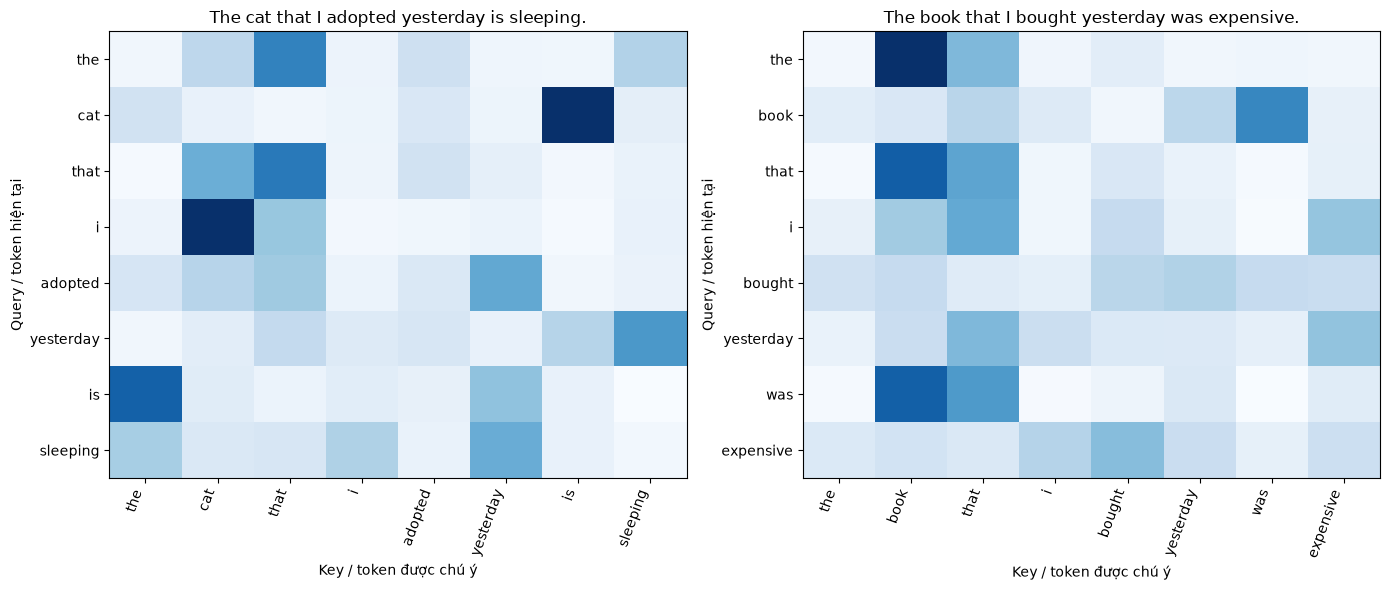

,Câu,Query token,Key token,Attention weight
0,The cat that I adopted yesterday is sleeping.,cat,is,0.590613
1,The cat that I adopted yesterday is sleeping.,cat,the,0.115087
2,The cat that I adopted yesterday is sleeping.,cat,adopted,0.092075
3,The cat that I adopted yesterday is sleeping.,cat,sleeping,0.060777
4,The cat that I adopted yesterday is sleeping.,cat,cat,0.046115
5,The cat that I adopted yesterday is sleeping.,adopted,yesterday,0.311391
6,The cat that I adopted yesterday is sleeping.,adopted,that,0.220266
7,The cat that I adopted yesterday is sleeping.,adopted,cat,0.176279
8,The cat that I adopted yesterday is sleeping.,adopted,the,0.101738
9,The cat that I adopted yesterday is sleeping.,adopted,adopted,0.087953


Đã lưu heatmap tại: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab06\attention_heatmap.png


In [15]:
visualization_sentences = [
    "The cat that I adopted yesterday is sleeping.",
    "The book that I bought yesterday was expensive.",
]
attention_visualization_rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for axis, sentence in zip(axes, visualization_sentences):
    tokens, probability, matrix = predict_attention_review(
        sentence, attention_run["model"]
    )
    axis.imshow(matrix, cmap="Blues", aspect="auto")
    axis.set_xticks(range(len(tokens)), labels=tokens, rotation=70, ha="right")
    axis.set_yticks(range(len(tokens)), labels=tokens)
    axis.set_xlabel("Key / token được chú ý")
    axis.set_ylabel("Query / token hiện tại")
    axis.set_title(sentence)

    target_tokens = (
        ["cat", "adopted", "sleeping"]
        if "cat" in tokens
        else ["book", "bought", "expensive"]
    )
    for target in target_tokens:
        if target not in tokens:
            continue
        query_index = tokens.index(target)
        top_indices = np.argsort(matrix[query_index])[-5:][::-1]
        for key_index in top_indices:
            attention_visualization_rows.append({
                "Câu": sentence,
                "Query token": target,
                "Key token": tokens[key_index],
                "Attention weight": matrix[query_index, key_index],
            })

fig.tight_layout()
fig.savefig(ATTENTION_HEATMAP_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

display(pd.DataFrame(attention_visualization_rows))
print(f"Đã lưu heatmap tại: {ATTENTION_HEATMAP_PATH}")


**Nhận xét — Experiment 3**

Chọn cat/adopted/sleeping và book/bought/expensive; ghi token được chú ý trong output. Đây chỉ là attention pattern, chưa phải giải thích ngôn ngữ hay bằng chứng reasoning.

Nhận xét: Với cat, weight cao nhất hướng tới is (0,591); adopted chú ý nhất yesterday (0,311); sleeping chú ý nhất yesterday (0,301). Ở câu kia, book chú ý nhất was (0,382), bought chú ý nhất yesterday (0,182), còn expensive chú ý nhất bought (0,247). Đây là pattern của model trên hai câu, không đủ để kết luận model hiểu quan hệ ngữ pháp.

## 15. Experiment 4 — LSTM context và Attention context

So sánh validation metrics trước; sau đó báo cáo test metrics của cả hai checkpoint. Model cho confusion matrix được chọn theo validation macro F1.

In [16]:
model_runs = {
    "LSTM": lstm_run,
    "Attention": attention_run,
}
validation_rows = []
for run in model_runs.values():
    row = add_model_result(
        run, "validation", run["validation_metrics"]
    )
    validation_rows.append(row)
    add_result_row(
        "Experiment 4 - Model comparison",
        model=run["name"],
        representation=row["representation"],
        split="validation",
        accuracy=row["accuracy"],
        precision_positive=row["precision_positive"],
        recall_positive=row["recall_positive"],
        f1_positive=row["f1_positive"],
        f1_macro=row["f1_macro"],
        validation_loss=run["validation_loss"],
        training_time_seconds=run["training_seconds"],
        epochs_trained=run["epochs_trained"],
        parameters=run["parameters"],
        sequence_length=BASE_MAX_LENGTH,
        vocabulary_size=VOCAB_SIZE,
        notes=f"Best checkpoint epoch {run['best_epoch']}.",
    )

validation_comparison = pd.DataFrame(validation_rows)
display(validation_comparison[[
    "model", "accuracy", "precision_positive", "recall_positive",
    "f1_macro", "training_time_seconds", "epochs_trained", "parameters",
]])


,model,accuracy,precision_positive,recall_positive,f1_macro,training_time_seconds,epochs_trained,parameters
0,LSTM,0.797398,0.804348,0.788025,0.797390,327.671941,5,1953345
1,Attention,0.820996,0.804257,0.850311,0.820806,31.750477,5,1932353


**Nhận xét — Experiment 4**

Hai model dùng cùng split và hyperparameters. So sánh F1, thời gian, số tham số và cách tạo context; attention không cần phải thắng LSTM.

Nhận xét: Attention đạt test F1 macro 0,8198, cao hơn LSTM 0,7936; validation lần lượt 0,8208 và 0,7974. Attention train 31,75 giây với 1.932.353 tham số, còn LSTM 327,67 giây với 1.953.345 tham số. Attention tạo context bằng weighted combination các token; LSTM dùng hidden state cuối. Kết quả này chỉ đúng với thiết lập/dataset lần chạy này.

,model,accuracy,precision_positive,recall_positive,f1_macro,training_time_seconds,parameters
0,LSTM,0.793566,0.798007,0.788226,0.793565,327.671941,1953345
1,Attention,0.819988,0.804116,0.847900,0.819813,31.750477,1932353


Chọn theo validation macro F1: Attention


,Dự đoán: negative,Dự đoán: positive
Thật: negative,3911,1028
Thật: positive,757,4220


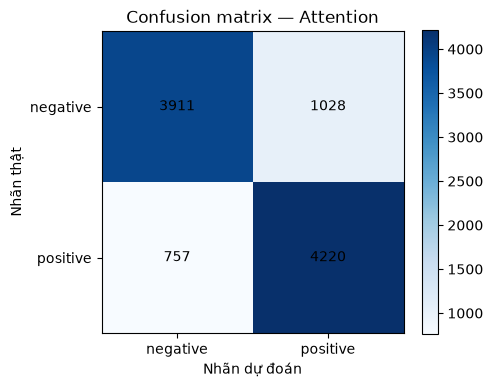

Đã lưu confusion matrix tại: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab06\confusion_matrix.png


In [17]:
_, _, test_loader = make_data_loaders()
test_comparison_rows = []
test_details = {}

for model_name, run in model_runs.items():
    test_loss, test_metrics, targets, predictions, probabilities = evaluate_model(
        run["model"], test_loader, nn.BCEWithLogitsLoss()
    )
    test_details[model_name] = {
        "targets": targets,
        "predictions": predictions,
        "probabilities": probabilities,
    }
    test_row = add_model_result(run, "test", test_metrics)
    test_row["test_loss"] = test_loss
    test_comparison_rows.append(test_row)
    add_result_row(
        "Experiment 4 - Model comparison",
        model=model_name,
        representation=test_row["representation"],
        split="test",
        accuracy=test_metrics["accuracy"],
        precision_positive=test_metrics["precision_positive"],
        recall_positive=test_metrics["recall_positive"],
        f1_positive=test_metrics["f1_positive"],
        f1_macro=test_metrics["f1_macro"],
        validation_loss=run["validation_loss"],
        test_loss=test_loss,
        training_time_seconds=run["training_seconds"],
        epochs_trained=run["epochs_trained"],
        parameters=run["parameters"],
        sequence_length=BASE_MAX_LENGTH,
        vocabulary_size=VOCAB_SIZE,
        notes="Test chỉ dùng để báo cáo; checkpoint đã chọn theo validation.",
    )

test_comparison = pd.DataFrame(test_comparison_rows)
display(test_comparison[[
    "model", "accuracy", "precision_positive", "recall_positive",
    "f1_macro", "training_time_seconds", "parameters",
]])

selected_model_name = max(
    model_runs,
    key=lambda name: model_runs[name]["validation_metrics"]["f1_macro"],
)
selected_run = model_runs[selected_model_name]
selected_test = test_details[selected_model_name]
print("Chọn theo validation macro F1:", selected_model_name)

matrix = confusion_matrix(
    selected_test["targets"],
    selected_test["predictions"],
    labels=[0, 1],
)
display(pd.DataFrame(
    matrix,
    index=["Thật: negative", "Thật: positive"],
    columns=["Dự đoán: negative", "Dự đoán: positive"],
))

fig, axis = plt.subplots(figsize=(5, 4))
image = axis.imshow(matrix, cmap="Blues")
axis.set_xticks([0, 1], labels=["negative", "positive"])
axis.set_yticks([0, 1], labels=["negative", "positive"])
axis.set_xlabel("Nhãn dự đoán")
axis.set_ylabel("Nhãn thật")
axis.set_title(f"Confusion matrix — {selected_model_name}")
for row_index in range(2):
    for column_index in range(2):
        axis.text(
            column_index, row_index, str(matrix[row_index, column_index]),
            ha="center", va="center",
        )
fig.colorbar(image, ax=axis)
fig.tight_layout()
fig.savefig(CONFUSION_MATRIX_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu confusion matrix tại: {CONFUSION_MATRIX_PATH}")


## 16. Experiment 5 — Sequence length và computational cost

Tính số phần tử của score/attention matrix. Memory estimate dưới đây chỉ là một matrix float32 cho một sequence; không gồm batch, gradients hay model parameters.

,Sequence length T,Attention matrix,Số phần tử T^2,Ước lượng memory float32 (MB)
0,10,10 x 10,100,0.000381
1,100,100 x 100,10000,0.038147
2,500,500 x 500,250000,0.953674
3,1000,1000 x 1000,1000000,3.814697
4,10000,10000 x 10000,100000000,381.469727


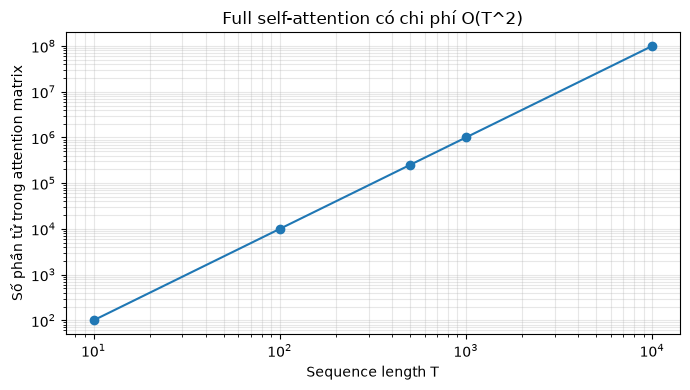

In [18]:
SEQUENCE_LENGTHS = [10, 100, 500, 1000, 10000]
cost_rows = []

for length in SEQUENCE_LENGTHS:
    elements = length ** 2
    cost_rows.append({
        "Sequence length T": length,
        "Attention matrix": f"{length} x {length}",
        "Số phần tử T^2": elements,
        "Ước lượng memory float32 (MB)": elements * 4 / (1024 ** 2),
    })
    add_result_row(
        "Experiment 5 - Attention cost",
        model="Full self-attention",
        representation="T x T score matrix",
        sequence_length=length,
        attention_matrix_elements=elements,
        notes=f"One float32 matrix ~{elements * 4 / (1024 ** 2):.4f} MB.",
    )

cost_table = pd.DataFrame(cost_rows)
display(cost_table)

fig, axis = plt.subplots(figsize=(7, 4))
axis.plot(
    cost_table["Sequence length T"],
    cost_table["Số phần tử T^2"],
    marker="o",
)
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("Sequence length T")
axis.set_ylabel("Số phần tử trong attention matrix")
axis.set_title("Full self-attention có chi phí O(T^2)")
axis.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()


**Nhận xét — Experiment 5**

Từ bảng T và T², giải thích vì sao full self-attention tốn bộ nhớ/tính toán khi sequence rất dài.

Nhận xét: Tăng T gấp 10 lần làm matrix tăng 100 lần: từ 1 triệu phần tử ở T=1.000 lên 100 triệu ở T=10.000. Một matrix float32 tương ứng khoảng 3,81 MB và 381,47 MB; thực tế còn cần bộ nhớ cho batch, gradient và activations. Vì vậy chi phí tăng theo O(T²).

## 17. Application — Context-aware sentiment

Dùng attention-based model cho ba câu của đề. In prediction, xác suất positive và các token nhận attention trung bình cao; heatmap vẫn chỉ là pattern quan sát.

,Review,Dự đoán,Xác suất positive,Top attended tokens
0,I like this movie.,negative,0.008089,"i (0.351), like (0.244), movie (0.214), this (..."
1,I do not like this movie.,negative,0.010456,"not (0.342), like (0.200), do (0.160), i (0.14..."
2,"I thought this movie would be bad, but it was ...",positive,0.616429,"excellent (0.215), but (0.143), actually (0.12..."


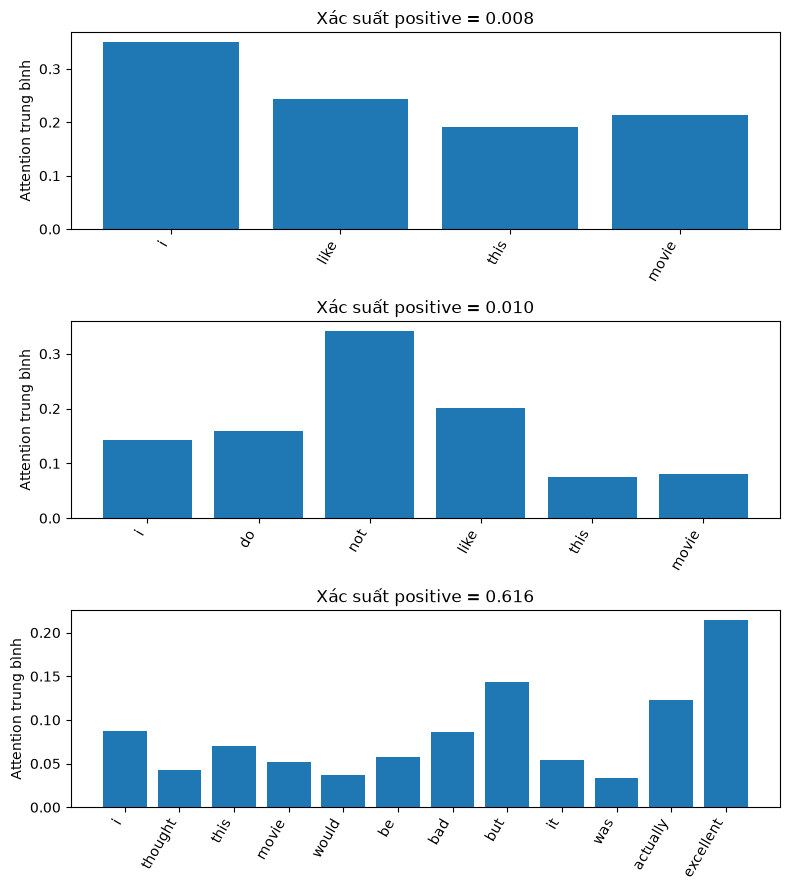

In [19]:
application_reviews = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent.",
]

application_rows = []
application_attention = []
for review in application_reviews:
    tokens, positive_probability, attention_matrix = predict_attention_review(
        review, attention_run["model"]
    )
    prediction = "positive" if positive_probability >= 0.5 else "negative"
    mean_attention = attention_matrix.mean(axis=0)
    top_indices = np.argsort(mean_attention)[-5:][::-1]
    top_tokens = [
        f"{tokens[index]} ({mean_attention[index]:.3f})"
        for index in top_indices
    ]
    application_rows.append({
        "Review": review,
        "Dự đoán": prediction,
        "Xác suất positive": positive_probability,
        "Top attended tokens": ", ".join(top_tokens),
    })
    application_attention.append(
        (tokens, attention_matrix, positive_probability)
    )
    add_result_row(
        "Application - Context-aware sentiment",
        model="Attention",
        representation="Self-attention context",
        split="new review",
        precision_positive=np.nan,
        recall_positive=np.nan,
        notes=(
            f"Prediction={prediction}; P(positive)="
            f"{positive_probability:.4f}; top tokens={top_tokens}"
        ),
    )

application_table = pd.DataFrame(application_rows)
display(application_table)

fig, axes = plt.subplots(
    len(application_attention), 1,
    figsize=(max(8, BASE_MAX_LENGTH * 0.06), 3 * len(application_attention)),
)
if len(application_attention) == 1:
    axes = [axes]
for axis, (tokens, attention_matrix, probability) in zip(
    axes, application_attention
):
    mean_attention = attention_matrix.mean(axis=0)
    axis.bar(range(len(tokens)), mean_attention)
    axis.set_xticks(range(len(tokens)), labels=tokens, rotation=60, ha="right")
    axis.set_ylabel("Attention trung bình")
    axis.set_title(f"Xác suất positive = {probability:.3f}")
fig.tight_layout()
plt.show()
plt.close(fig)


**Nhận xét — Application**

Với từng câu, token/context nào có thể liên quan tới prediction? So sánh câu phủ định và câu contrast.

Nhận xét: I like this movie bị dự đoán negative (P(positive)=0,008); attention trung bình cao ở i, like, movie. Câu I do not like this movie cũng negative (0,010), trọng số tập trung ở not và like. Câu contrast được dự đoán positive (0,616), với excellent và but nằm trong nhóm được chú ý. Trọng số chỉ cho biết pattern; không chứng minh token đó là nguyên nhân duy nhất của prediction.

## 18. Error analysis — lỗi của attention classifier

Chọn ít nhất 3 correct và 3 incorrect từ test của attention model. Top attended tokens là trung bình theo query và chỉ mô tả trọng số; hãy tự nhận xét nguyên nhân lỗi trong error_analysis.md.

In [20]:
attention_test = test_details["Attention"]
attention_error_frame = pd.DataFrame({
    "Text": x_test,
    "True": np.where(attention_test["targets"] == 1, "positive", "negative"),
    "Predicted": np.where(
        attention_test["predictions"] == 1, "positive", "negative"
    ),
})
attention_error_frame["Correct"] = (
    attention_error_frame["True"] == attention_error_frame["Predicted"]
)

correct_examples = attention_error_frame[
    attention_error_frame["Correct"]
].sample(
    n=min(3, int(attention_error_frame["Correct"].sum())),
    random_state=RANDOM_STATE,
)
incorrect_examples = attention_error_frame[
    ~attention_error_frame["Correct"]
].sample(
    n=min(3, int((~attention_error_frame["Correct"]).sum())),
    random_state=RANDOM_STATE,
)

def top_attention_tokens(review, model, top_n=5):
    tokens, _, matrix = predict_attention_review(review, model)
    mean_weights = matrix.mean(axis=0)
    selected = np.argsort(mean_weights)[-top_n:][::-1]
    return ", ".join(
        f"{tokens[index]} ({mean_weights[index]:.3f})"
        for index in selected
    )

correct_examples = correct_examples.copy()
correct_examples["Attention top tokens"] = correct_examples["Text"].map(
    lambda text: top_attention_tokens(text, attention_run["model"])
)
incorrect_examples = incorrect_examples.copy()
incorrect_examples["Attention top tokens"] = incorrect_examples["Text"].map(
    lambda text: top_attention_tokens(text, attention_run["model"])
)
print("Ví dụ attention classifier phân loại đúng")
display(correct_examples[["Text", "True", "Predicted", "Attention top tokens"]])
print("Ví dụ attention classifier phân loại sai")
display(incorrect_examples[["Text", "True", "Predicted", "Attention top tokens"]])


Ví dụ attention classifier phân loại đúng


,Text,True,Predicted,Attention top tokens
1601,pathetic. this is what happens when director c...,negative,negative,"pathetic (0.061), great (0.039), no (0.023), h..."
1908,this movie is one among the very few indian mo...,positive,positive,"artificially (0.038), excellent (0.035), taken..."
4886,"from the opening shots of the lead actor, we a...",positive,positive,"throughout (0.047), director (0.034), many (0...."


Ví dụ attention classifier phân loại sai


,Text,True,Predicted,Attention top tokens
7523,i just finished watching disappearances at afi...,negative,positive,"canadian (0.041), wild (0.032), lack (0.024), ..."
5982,up until around 1970 lucille ball was one grea...,negative,positive,"great (0.047), perfect (0.037), physically (0...."
8303,"after the usual chase scene, jerry accidentall...",positive,negative,"deceiving (0.046), think (0.033), milk (0.027)..."


## 19. Lưu kết quả

Lưu các số liệu đã tính vào results.csv. Notebook không điền trước phần giải thích trong error_analysis.md hoặc reflection.md.

In [21]:
results_df = pd.DataFrame(results_rows, columns=RESULT_COLUMNS)
results_df = results_df.drop_duplicates()
results_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8-sig")
display(results_df)
print(f"Đã lưu bảng kết quả: {RESULTS_PATH}")
print(f"Attention heatmap: {ATTENTION_HEATMAP_PATH}")
print(f"Confusion matrix: {CONFUSION_MATRIX_PATH}")


,experiment,model,representation,split,accuracy,precision_positive,recall_positive,f1_positive,f1_macro,validation_loss,...,vocabulary_size,temperature,max_attention_weight,attention_entropy,attention_matrix_elements,query,token,score,attention_weight,notes
0,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,The,1.900405,0.290405,"Vector minh họa, không phải model đã train."
1,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,movie,-1.516604,0.009528,"Vector minh họa, không phải model đã train."
2,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,was,-1.078044,0.014773,"Vector minh họa, không phải model đã train."
3,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,surprisingly,-2.634276,0.003116,"Vector minh họa, không phải model đã train."
4,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,good,0.436586,0.067186,"Vector minh họa, không phải model đã train."
5,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,despite,0.501018,0.071657,"Vector minh họa, không phải model đã train."
6,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,a,1.462285,0.187384,"Vector minh họa, không phải model đã train."
7,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,very,1.836904,0.272538,"Vector minh họa, không phải model đã train."
8,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,slow,0.451789,0.068215,"Vector minh họa, không phải model đã train."
9,Experiment 1 - Attention distribution,Dummy query,Dot-product attention,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.290405,1.768849,NaN,seeded dummy,beginning,-1.049685,0.015198,"Vector minh họa, không phải model đã train."


Đã lưu bảng kết quả: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab06\results.csv
Attention heatmap: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab06\attention_heatmap.png
Confusion matrix: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab06\confusion_matrix.png
